In [22]:
import torch
import numpy as np 
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
import math
import cvxpy as cp

DATA GENERATION -> 3 clusters with 2D normal distribution

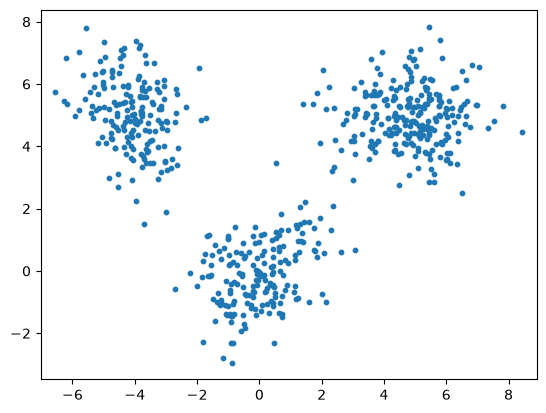

In [24]:
rng = np.random.default_rng(42)

# True GMM parameters
true_means = np.array([
    [0 , 0],
    [5 , 5],
    [-4, 5]
])

true_covariances = np.array([
    [[1, 0.3] , [0.3, 1]],
    [[1.5, 0], [0, 0.8]],
    [[0.8, -0.2], [-0.2, 1.2]]
])

true_weights = np.array([0.3, 0.4, 0.3])

n = 600
K = 3

# Tirage des variable lattente 
Z = rng.choice(K, size=n, p=true_weights)

# Data generation 
X = np.array([
    rng.multivariate_normal(true_means[k], true_covariances[k])
    for k in Z
    ])

plt.scatter(X[:,0], X[:,1], s=10)
plt.axis('equal')
plt.show()

In [25]:
# Initialisation du tenseur pour les data du GMM X
x_torch = torch.tensor(X,dtype=torch.float64,requires_grad=True)
n, d = x_torch.shape
K = 3

print(x_torch.shape)
print(x_torch.requires_grad)

torch.Size([600, 2])
True


Fonction de l'algo EM 

In [26]:
def initialization_torch(x, K, rng):
    """Initialize the parameters of the GMM"""
    n, d = x.shape

    # Initialize weights
    weights = torch.ones(K, dtype=x.dtype, device=x.device) / K

    # Randomly select K observations as initial means
    indices = rng.choice(n, K, replace=False)
    means = x[indices].detach().clone()

    # Initialize covariance matrices
    covariances = torch.eye(d, dtype=x.dtype, device=x.device).repeat(K, 1, 1)

    return weights, means, covariances

def gaussian_log_density_torch(x, mean, cov):
    n, d = x.shape

    diff = x - mean

    # Solve Sigma @ z = diff.T
    solved = torch.linalg.solve(cov, diff.T).T

    quadratic = torch.sum(diff * solved, dim=1)

    sign, logdet = torch.linalg.slogdet(cov)

    return -0.5 * (
        d * math.log(2 * math.pi)
        + logdet
        + quadratic
    )

## Le fait de passer au log evite les probleme lie au tres petite proba
def e_step_torch(x, weights, means, covariances) : 
    """E-step, compute responsibilities."""
    K = len(weights)
    
    log_gamma = torch.stack([
        torch.log(weights[k]) + gaussian_log_density_torch(x,means[k],covariances[k])
        for k in range(K)
    ], dim=1)
    
    log_normalization = torch.logsumexp(log_gamma, dim=1, keepdim=True)
    gamma = torch.exp(log_gamma - log_normalization)
    
    return gamma 

def m_step_torch(x, responsibilities ) : 
    """M-step, update of the parameters"""
    n, d = x.shape  #(n, d) 
    K = responsibilities.shape[1] # responsibilities (n,K)
    
    normalization = torch.sum(responsibilities, dim= 0)   #(K,)

    # update weights
    new_weights = normalization / n  #(K,)
    
    # update mean
    new_means = (responsibilities.T @ x) / normalization[:,None]     #(K,d)
    
    # update covariance
    covariance_list = []
    for k in range(K) : 
        diff = (x - new_means[k])    #(n,d)
        weighted_diff = responsibilities[:, k, None] * diff   #(n,d)
        cov_k = (diff.T @ weighted_diff ) / normalization[k] #(d,d)
        covariance_list.append(cov_k)
        
    new_covariances = torch.stack(covariance_list, dim=0)
    eps = 1e-6
    new_covariances = new_covariances + eps * torch.eye(d, dtype = x.dtype, device= x.device).unsqueeze(0)
        
    
    return [new_weights, new_means, new_covariances]

def log_likelihood_torch(x,weights,means,covariances) : 
    """Compute the log-likelihood"""
    K = len(weights)
    
    log_p = torch.stack([
        torch.log(weights[k]) + gaussian_log_density_torch(x,means[k],covariances[k])
        for k in range(K)
    ], dim=1)
    

    return torch.logsumexp(log_p, dim=1).sum()

def em_algorithm_torch(x, weights, means, covariances, n_iter = 100) : 
    """Run of the Expectation-Maximization Algo"""
    history = []
    
    for i in range(n_iter) : 
        # E-step
        responsibilities = e_step_torch(x,weights= weights, means= means, covariances= covariances)
        #M-step
        weights, means, covariances = m_step_torch(x,responsibilities= responsibilities)
        #compute log-likelihood
        log_likelihood = log_likelihood_torch(x,weights=weights,means=means,covariances=covariances)
        history.append(log_likelihood.item())
    
    return weights, means, covariances, history

def em_algo_with_fixed_weight(x,weights,means ,covariances,n_iter=100) : 
    """Run of Expectation-Maximization algorithm with fixed weights"""
    history = []
    for _ in range(n_iter) :
        # E-step 
        responsibilities = e_step_torch(x,weights,means,covariances)
        #M-step 
        _ , means, covariances = m_step_torch(x,responsibilities= responsibilities)
        #compute log-likelihood
        log_likelihood = log_likelihood_torch(x,weights,means,covariances)
        history.append(log_likelihood.item())
    
    return weights, means, covariances, history

Test of the E-M algo <br>
-> test weight, mean, cov prediction <br>
-> test of the log-likelihood convergence

Estimated weights: [0.29168694 0.30334908 0.40496398]
True weights: [0.3 0.4 0.3]
Estimated means: [[-4.0794168   5.03605073]
 [-0.00868232 -0.10009177]
 [ 4.80864809  4.95411073]]
True means: [[ 0  0]
 [ 5  5]
 [-4  5]]
Estimated covariances: [[[ 0.76300413 -0.27614611]
  [-0.27614611  1.29931316]]

 [[ 1.13317086  0.39775747]
  [ 0.39775747  1.10579732]]

 [[ 1.43553648  0.00218501]
  [ 0.00218501  0.86914987]]]
True covariances: [[[ 1.   0.3]
  [ 0.3  1. ]]

 [[ 1.5  0. ]
  [ 0.   0.8]]

 [[ 0.8 -0.2]
  [-0.2  1.2]]]


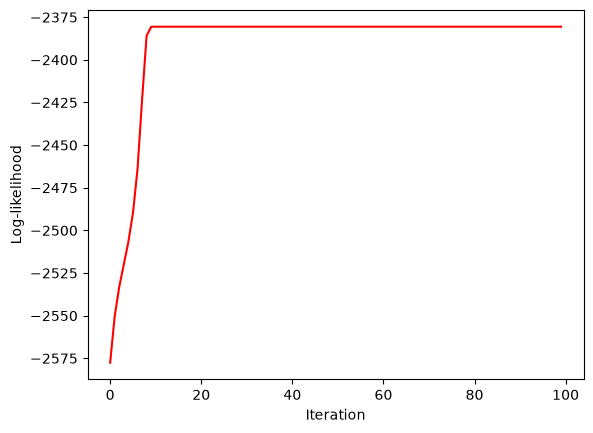

In [27]:
n_iter = 100

# Initialization directly in PyTorch
em_initial_weights, em_initial_means, em_initial_covariances = initialization_torch(x_torch, K, rng)

# Run differentiable EM
em_weights, em_means, em_covariances, em_history = em_algorithm_torch(
    x=x_torch,
    weights=em_initial_weights,
    means=em_initial_means,
    covariances=em_initial_covariances,
    n_iter=n_iter
)

# Results
print("Estimated weights:", em_weights.detach().numpy())
print("True weights:", true_weights)

print("Estimated means:", em_means.detach().numpy())
print("True means:", true_means)

print("Estimated covariances:", em_covariances.detach().numpy())
print("True covariances:", true_covariances)

# Plot log-likelihood
plt.plot(em_history, color="red")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.show()

Test of the differenciability <br>
-> comparaison of autograd diff and the real gradiant of the loss function

In [28]:
# Test de différentiabilité
em_test_loss = em_means.square().sum()

em_gradient = torch.autograd.grad(em_test_loss, x_torch)[0]

print("Gradient shape:", em_gradient.shape)
print("Gradient norm:", em_gradient.norm().item())
print("All finite:", torch.isfinite(em_gradient).all().item())

Gradient shape: torch.Size([600, 2])
Gradient norm: 1.3565045418507147
All finite: True


In [29]:
# Direction aléatoire de norme 1 dans l'espace des données
generator = torch.Generator(device=x_torch.device).manual_seed(42)
em_direction = torch.randn(
    x_torch.shape,
    dtype=x_torch.dtype,
    device=x_torch.device,
    generator=generator,
)
em_direction = em_direction / em_direction.norm()

# Dérivée directionnelle prédite par autograd
em_autograd_value = (em_gradient * em_direction).sum()

@torch.no_grad()
def em_loss_at(x):
    _, fitted_means, _, _ = em_algorithm_torch(
        x=x, weights=em_initial_weights, means=em_initial_means, covariances=em_initial_covariances, n_iter=n_iter
    )
    return fitted_means.square().sum()

for h in (1e-3, 1e-4, 1e-5):
    em_finite_difference = (
        em_loss_at(x_torch + h * em_direction)
        - em_loss_at(x_torch - h * em_direction)
    ) / (2 * h)

    error = (em_autograd_value - em_finite_difference).abs().item()
    print(f"h={h:.0e} | autograd={em_autograd_value.item():.10f} "
          f"| finite diff={em_finite_difference.item():.10f} | error={error:.2e}")

h=1e-03 | autograd=-0.0477173987 | finite diff=-0.0477173987 | error=2.09e-12
h=1e-04 | autograd=-0.0477173987 | finite diff=-0.0477173986 | error=1.02e-10
h=1e-05 | autograd=-0.0477173987 | finite diff=-0.0477173941 | error=4.58e-09


Implementation Optimal transport function

In [30]:
def sqrt_sigma(sigma) : 
    """Compute the matrix square root using spectral decomposition."""
    eigenvalues, eigenvectors = torch.linalg.eigh(sigma)
    sqrt_eigenvalues = torch.sqrt(eigenvalues)
    sqrt_eigenvalue_matrix = torch.diag(sqrt_eigenvalues)
    spectral_decomposition = eigenvectors @ sqrt_eigenvalue_matrix @ eigenvectors.T
    return spectral_decomposition

def wasserstein2_dist(gaussian_1, gaussian_2) : 
    """Compute the squared Wasserstein-2 distance between two Gaussian measures."""
    diff_mean = (gaussian_1[0] - gaussian_2[0])
    norm_diff_mean = diff_mean.square().sum()
    
    sqrt_cov_1 = sqrt_sigma(gaussian_1[1])
    eigh_right = torch.linalg.eigvalsh(sqrt_cov_1 @ gaussian_2[1] @ sqrt_cov_1)
    bures_dist_2 = torch.sum(torch.sqrt(eigh_right))

    trace = torch.trace(gaussian_1[1] + gaussian_2[1]) - (2 * bures_dist_2)
    
    return norm_diff_mean + trace

def cost_matrix(gmm_1, gmm_2) : 
    """"Computation of the cost matrix for the kantorovich problem"""
    costs = []
    for i in range(len(gmm_1[0])) : 
        cost_row = []
        for j in range(len(gmm_2[0])) : 
            cost_row.append(wasserstein2_dist((gmm_1[1][i],gmm_1[2][i]), (gmm_2[1][j],gmm_2[2][j])))
        cost_row = torch.stack(cost_row,dim=0)
        costs.append(cost_row)
    costs = torch.stack(costs, dim=0)
    return costs
    

def MW2(gmm_1, gmm_2) : 
    """Compute the squared mixture Wasserstein-2 cost between two GMMs."""
    
    transport_plan = cp.Variable((len(gmm_1[0]),len(gmm_2[0])))
    constraints = [
        transport_plan >= 0, 
        cp.sum(transport_plan, axis=1) == gmm_1[0].detach().cpu().numpy(),
        cp.sum(transport_plan, axis=0) == gmm_2[0].detach().cpu().numpy()
    ]
    costs = cost_matrix(gmm_1,gmm_2)
    objective = cp.Minimize(cp.sum(cp.multiply(transport_plan,costs.detach().cpu().numpy())))
    problem = cp.Problem(objective=objective,constraints=constraints)
    
    optimal_cost = problem.solve()
    if transport_plan.value is None:
        raise RuntimeError(f"Échec du solveur OT : {problem.status}")

    optimal_plan = costs.new_tensor(transport_plan.value)
    loss = (optimal_plan * costs).sum()
    
    return optimal_cost, optimal_plan, loss
           
        

Distance between two GMM using MW2 <br>
-> First case : between the same GMM <br>
-> Seconde case : betwen a GMM and a translation of this GMM

In [31]:
gmm_em = (em_weights, em_means, em_covariances)
weights_em_np = em_weights.detach().cpu().numpy()
expected_plan = np.diag(weights_em_np)

# Même GMM des deux côtés
with torch.no_grad():
    self_cost, self_plan, _ = MW2(gmm_em, gmm_em)

assert self_plan is not None, "CVXPY n'a pas renvoyé de plan."
np.testing.assert_allclose(self_cost, 0.0, atol=1e-6, rtol=0)
np.testing.assert_allclose(self_plan, expected_plan, atol=1e-6, rtol=0)
print(f"Même GMM      | MW2² = {self_cost:.8f}")

# Même GMM translaté de (1, -0.5)
shift = em_means.new_tensor([1.0, -0.5])
gmm_shifted = (em_weights, em_means + shift, em_covariances)

with torch.no_grad():
    shifted_cost, shifted_plan, _  = MW2(gmm_em, gmm_shifted)

assert shifted_plan is not None, "CVXPY n'a pas renvoyé de plan."
np.testing.assert_allclose(shifted_plan.sum(axis=1), weights_em_np, atol=1e-6)
np.testing.assert_allclose(shifted_plan.sum(axis=0), weights_em_np, atol=1e-6)
np.testing.assert_allclose(shifted_plan, expected_plan, atol=1e-6, rtol=0)
np.testing.assert_allclose(shifted_cost, 1.25, atol=1e-6, rtol=0)
print(f"GMM translaté | MW2² = {shifted_cost:.8f}")
print("Tests du coût et du plan optimal OK")

Même GMM      | MW2² = -0.00000002
GMM translaté | MW2² = 1.24999998
Tests du coût et du plan optimal OK


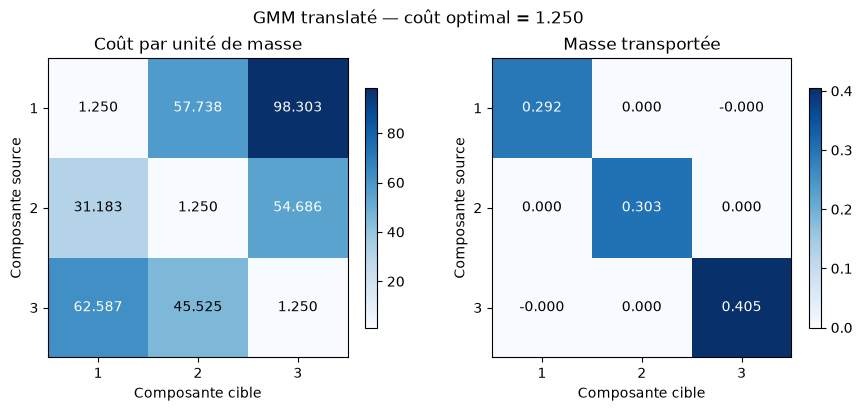

In [32]:
with torch.no_grad():
    shifted_cost_matrix = cost_matrix(gmm_em, gmm_shifted).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)

for ax, matrix, title in [
    (axes[0], shifted_cost_matrix, "Coût par unité de masse"),
    (axes[1], shifted_plan, "Masse transportée"),
]:
    image = ax.imshow(matrix, cmap="Blues")
    fig.colorbar(image, ax=ax, shrink=0.8)

    n_source, n_target = matrix.shape
    ax.set_xticks(range(n_target), labels=range(1, n_target + 1))
    ax.set_yticks(range(n_source), labels=range(1, n_source + 1))
    ax.set_xlabel("Composante cible")
    ax.set_ylabel("Composante source")
    ax.set_title(title)

    for i in range(n_source):
        for j in range(n_target):
            value = matrix[i, j]
            color = "white" if value > matrix.max() / 2 else "black"
            ax.text(j, i, f"{value:.3f}", ha="center", va="center", color=color)

fig.suptitle(f"GMM translaté — coût optimal = {shifted_cost:.3f}")
plt.show()

Test of the diffenrent OT function used to compute MW2 <br>
-> test if the gradient steel good <br>
-> test of the cost matrix <br>
-> comparaison between autograde diff and the real gradient

In [33]:
dtype = torch.float64
test_mean = torch.zeros(2, dtype=dtype)

# 1. Vérifier la valeur de W₂²
identity = torch.eye(2, dtype=dtype)
cost = wasserstein2_dist((test_mean, identity), (test_mean, 4 * identity))

torch.testing.assert_close(cost, torch.tensor(2.0, dtype=dtype))
print(f"Test de valeur OK — W₂² = {cost.item():.8f}")

# 2. Vérifier le gradient par rapport à la première covariance
test_covariance_1 = torch.tensor(
    [[2.0, 0.3], [0.3, 1.0]], dtype=dtype, requires_grad=True
)
test_covariance_2 = torch.tensor([[1.0, -0.2], [-0.2, 3.0]], dtype=dtype)

covariance_direction = torch.tensor([[0.4, 0.2], [0.2, -0.3]], dtype=dtype)
covariance_direction = covariance_direction / covariance_direction.norm()

cost = wasserstein2_dist((test_mean, test_covariance_1), (test_mean, test_covariance_2))
(covariance_gradient,) = torch.autograd.grad(cost, test_covariance_1)
covariance_autograd_value = (covariance_gradient * covariance_direction).sum()

h = 1e-5
with torch.no_grad():
    cost_plus = wasserstein2_dist((test_mean, test_covariance_1 + h * covariance_direction), (test_mean, test_covariance_2))
    cost_minus = wasserstein2_dist((test_mean, test_covariance_1 - h * covariance_direction), (test_mean, test_covariance_2))
    covariance_finite_difference = (cost_plus - cost_minus) / (2 * h)

print(f"Autograd         = {covariance_autograd_value.item():.10f}")
print(f"Différence finie = {covariance_finite_difference.item():.10f}")
print(f"Erreur absolue   = {(covariance_autograd_value - covariance_finite_difference).abs().item():.2e}")

torch.testing.assert_close(covariance_autograd_value, covariance_finite_difference, rtol=1e-6, atol=1e-8)
print("Test du gradient OK")

# Test de la fonction cost matrix
dtype = torch.float64

test_weights = torch.tensor([0.3, 0.4, 0.3], dtype=dtype)
test_means = torch.tensor(
    [[0.0, 0.0], [3.0, 0.0], [0.0, 4.0]],
    dtype=dtype,
    requires_grad=True,
)
test_covariances = torch.eye(2, dtype=dtype).repeat(3, 1, 1)

gmm = (test_weights, test_means, test_covariances)
costs = cost_matrix(gmm, gmm)

expected = torch.tensor(
    [[0.0, 9.0, 16.0],
     [9.0, 0.0, 25.0],
     [16.0, 25.0, 0.0]],
    dtype=dtype,
)

torch.testing.assert_close(costs, expected)
print("Matrice de coûts OK")

(cost_gradient,) = torch.autograd.grad(costs[0, 1], test_means)
expected_gradient = torch.tensor(
    [[-6.0, 0.0], [6.0, 0.0], [0.0, 0.0]],
    dtype=dtype,
)

torch.testing.assert_close(cost_gradient, expected_gradient)
print("Gradient par rapport aux moyennes OK")

Test de valeur OK — W₂² = 2.00000000
Autograd         = 0.7227421883
Différence finie = 0.7227421882
Erreur absolue   = 8.03e-11
Test du gradient OK
Matrice de coûts OK
Gradient par rapport aux moyennes OK


4.2 section implementation <br>
-> compute MW2 with fixed points EM <br>
-> compute the gradiant of the loss at each step <br>
-> each step represente small step of X

Loss initiale : 1.250000
Loss au dernier pas enregistré : 0.083151


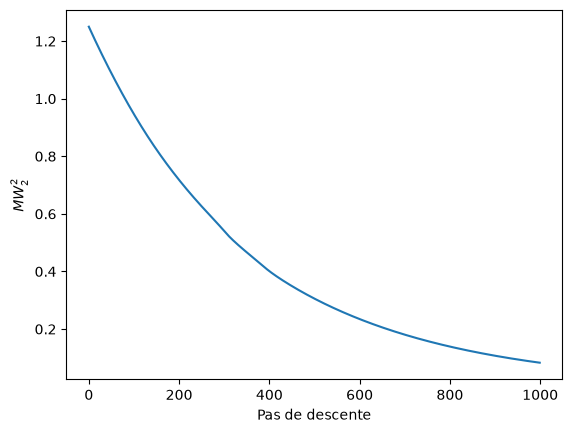

In [34]:
x_flow = x_torch.detach().clone().requires_grad_(True)
fixed_weights, initial_means, initial_covariances = initialization_torch(
    x_flow, K, np.random.default_rng(42)
)

# Construire la cible une seule fois à partir de X_0.
with torch.no_grad():
    initial_fitted_weights, initial_fitted_means, initial_fitted_covariances, _ = em_algo_with_fixed_weight(
        x_flow, fixed_weights, initial_means, initial_covariances, n_iter=n_iter
    )
    flow_shift = initial_fitted_means.new_tensor([1.0, -0.5])
    gmm_target = (initial_fitted_weights, initial_fitted_means + flow_shift, initial_fitted_covariances)

eta = 0.4
T = 1000
loss_history = []
trajectory = [x_flow.detach().cpu().numpy().copy()]

for _ in range(T):
    flow_weights, flow_means, flow_covariances, _ = em_algo_with_fixed_weight(
        x_flow, fixed_weights, initial_means, initial_covariances, n_iter
    )
    
    _, _, flow_loss = MW2((flow_weights,flow_means,flow_covariances), gmm_target)
    
    (flow_gradient,) = torch.autograd.grad(flow_loss, x_flow)
    loss_history.append(flow_loss.item())
    
    with torch.no_grad() : 
        x_flow.sub_(eta * flow_gradient)
        trajectory.append(x_flow.detach().cpu().numpy().copy())
    
    
   

print(f"Loss initiale : {loss_history[0]:.6f}")
print(f"Loss au dernier pas enregistré : {loss_history[-1]:.6f}")
plt.plot(loss_history)
plt.xlabel("Pas de descente")
plt.ylabel(r"$MW_2^2$")
plt.show()

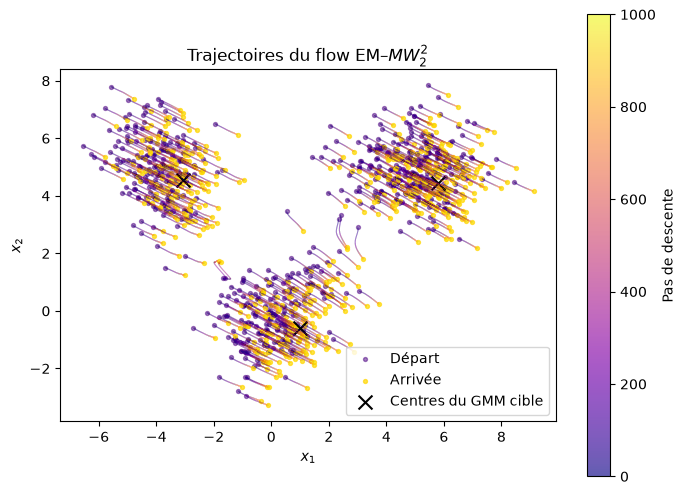

In [35]:
positions = np.stack(trajectory)  # (T + 1, n_points, 2)

# Relie la position de chaque point à sa position au pas suivant.
segments = np.stack((positions[:-1], positions[1:]), axis=2)
segments = segments.reshape(-1, 2, 2)
segment_steps = np.repeat(np.arange(1, len(positions)), positions.shape[1])

fig, ax = plt.subplots(figsize=(8, 6))

paths = LineCollection(
    segments,
    cmap="plasma",
    norm=Normalize(vmin=0, vmax=len(positions) - 1),
    linewidths=0.7,
    alpha=0.65,
)
paths.set_array(segment_steps)
ax.add_collection(paths)

ax.scatter(*positions[0].T, s=8, color="indigo", alpha=0.5, label="Départ")
ax.scatter(*positions[-1].T, s=8, color="gold", alpha=0.7, label="Arrivée")
ax.scatter(
    *gmm_target[1].detach().cpu().numpy().T,
    s=100, marker="x", color="black", label="Centres du GMM cible",
)

ax.autoscale()
ax.set_aspect("equal")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Trajectoires du flow EM–$MW_2^2$")
ax.legend()
fig.colorbar(paths, ax=ax, label="Pas de descente")
plt.show()